![Banner](../../../../Images/Banner/03_spatial_analysis/03_06_banner_spatial_analysis_Segregation.png)







# Segregation Over Time: Boundaries, Panels, and Decomposition






## Overview

Segregation research is mostly about change: did Buffalo integrate, and why? Two technical
problems stand between census tables and an answer.

1. **Boundaries move.** The Census Bureau redraws tracts every decade: Erie and Niagara counties had
   about 300 tracts in 2000 and 2010 and 325 in 2020, with many split, merged, or reshaped. Indices
   computed on different geographies are not comparable (the modifiable areal unit problem, MAUP).
2. **Change has more than one source.** An index can fall because people moved (the spatial
   arrangement changed) or because the metro area's group mix changed (composition). Policy
   implications differ, so the two need to be separated.

This notebook follows the PySAL tutorial on
[decomposition](https://pysal.org/segregation/tutorial.html) and extends it to a multi-period
panel with `seg.areal_interpolate`, `seg.dasymetric_interpolate`, `seg.harmonize_panel`,
`seg.compute_panel`, `seg.trend`, `seg.decompose_change`, and `seg.chain_decomposition`. It also
shows how the harmonized panel used in notebooks 03_07_01 to 03_07_06 was built.

Topics:

- Real tract boundary changes, 2000 to 2020, and the MAUP
- Areal and dasymetric interpolation with a housing-unit raster from census blocks
- Validating interpolation against block-level truth
- A harmonized panel with trend test
- Shapley decomposition of change into spatial and composition parts, chained across decades
- Exporting a tract-by-year panel for causal models






## Setup

The next cell finds the repository root, puts it on the import path, points `DATA` at
`Data/03_spatial_analysis/data_segregation/buffalo`, imports `geolattice.spatial_analysis.segregation` as `seg`, and loads
the data.

**Study area and data.** The Buffalo-Cheektowaga metropolitan area: Erie and Niagara counties,
New York (about 1.17 million people in 2020). Counts come from the U.S. Census Bureau decennial
censuses of 2000, 2010, and 2020, by census tract, for five mutually exclusive groups:

| Column | Census definition |
|---|---|
| `white` | Not Hispanic or Latino, White alone |
| `black` | Not Hispanic or Latino, Black or African American alone |
| `hispanic` | Hispanic or Latino (any race) |
| `asian` | Not Hispanic or Latino, Asian alone |
| `other` | Everyone else (other single races and two or more races) |

Tract boundaries change between censuses. To compare years on the same units, the 2000 and 2010
counts have been moved onto the 323 tracts of 2020 with dasymetric interpolation weighted by 2020
housing units; notebook 03_07_07 shows how. Tracts with fewer than 100 residents (water, parks,
the airport) are dropped. `Data/03_spatial_analysis/data_segregation/make_buffalo_data.py` rebuilds everything from
the Census files in `Data/03_spatial_analysis/data_segregation/`.

Two map helpers keep every map in the same frame: `add_context(ax)` draws the county outlines,
and `metro_and_core(...)` shows the whole metro area next to a 30 km window centred on the City
of Buffalo, where most tracts are small.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup and warning control.
import warnings  # silence noisy third-party warnings during demos
from pathlib import Path  # filesystem paths for locating sample data

# Third-party GIS / plotting / tabular stack used throughout the notebook.
import geopandas as gpd  # GeoDataFrame I/O for tracts and counties
import matplotlib.pyplot as plt  # figure and axes creation for maps
import numpy as np  # array ops for shares, norms, and masks
import pandas as pd  # tabular display of composition and indices
from IPython.display import display  # rich table previews in the notebook

# Hide library warnings so the notebook output stays readable.
warnings.filterwarnings("ignore")  # run this analysis or plotting step

# ===================================================================
# Setup for Buffalo metro segregation demos.
# Import GeoLattice, point DATA at Data/03_spatial_analysis/data_segregation/buffalo,
# import segregation as seg, load the tract panel, and define map helpers.
# ===================================================================

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Buffalo metro sample data (Erie + Niagara tracts on a shared 2020 geography).
DATA = ROOT / "Data" / "03_spatial_analysis" / "data_segregation" / "buffalo"  # define DATA

# Segregation indices, local measures, profiles, and inference helpers.
from geolattice.spatial_analysis import segregation as seg

# Compact figures with top/right spines removed for a cleaner look.
plt.rcParams.update(  # run this analysis or plotting step
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
GROUPS = ["white", "black", "hispanic", "asian"]  # main race/ethnicity count columns
ALL_GROUPS = GROUPS + ["other"]  # include residual other category in totals
YEARS = (2000, 2010, 2020)  # panel years available in the sample

# Panel on the 2020 tract geometry (2000 and 2010 interpolated onto it).
tracts = {  # define tracts
    2000: gpd.read_file(DATA / "tracts_2000_on2020.geojson"),  # 2000 counts on 2020 boundaries
    2010: gpd.read_file(DATA / "tracts_2010_on2020.geojson"),  # 2010 counts on 2020 boundaries
    2020: gpd.read_file(DATA / "tracts_2020.geojson"),  # native 2020 tracts
}
counties = gpd.read_file(DATA / "counties.geojson")  # Erie and Niagara outlines
CORE = (662_000, 4_738_000, 692_000, 4_768_000)  # 30 km window on the City of Buffalo (UTM 17N, m)
CITY_HALL = (673_249, 4_750_383)  # City Hall marker for the core window


def add_context(ax, core=False, labels=True):
    """Draw county boundaries and optionally zoom to the City of Buffalo window."""
    counties.boundary.plot(ax=ax, color="0.25", lw=0.8)  # county outlines for context
    if core:  # apply the city-window zoom when requested
        ax.set_xlim(CORE[0], CORE[2])  # zoom to city window
        ax.set_ylim(CORE[1], CORE[3])  # run this analysis or plotting step
        ax.plot(*CITY_HALL, marker="*", color="k", ms=9, mec="white")  # City Hall star
    elif labels:
        for name, (x, y) in {  # iterate over the collection
            "Niagara Co.": (690_000, 4_790_000),  # run this analysis or plotting step
            "Erie Co.": (700_000, 4_715_000),  # run this analysis or plotting step
        }.items():  # run this analysis or plotting step
            ax.text(x, y, name, fontsize=8, color="0.25", ha="center")  # run this analysis or plotting step
    ax.set_axis_off()  # hide coordinate ticks on maps
    return ax  # return the computed result


def metro_and_core(
    gdf, values, title="", cmap="RdBu_r", norm=None, vmin=None, vmax=None,
    label="", significant=None, axes=None,  # define label
):
    """Side-by-side metro-wide and city-window choropleths of the same values."""
    if axes is None:  # create defaults when the caller omitted them
        fig, axes = plt.subplots(  # run this analysis or plotting step
            1, 2, figsize=(13, 6.2),  # run this analysis or plotting step
            gridspec_kw={"width_ratios": [1, 1.25]},  # define gridspec_kw
            constrained_layout=True,  # define constrained_layout
        )
    else:
        fig = axes[0].figure  # figure handle
    g = gdf.assign(_v=np.asarray(values, dtype=float))  # attach plot column
    kw = dict(  # extra keyword arguments for compute()
        column="_v", cmap=cmap, norm=norm,  # define column
        vmin=None if norm else vmin, vmax=None if norm else vmax,  # define vmin
        edgecolor="white", linewidth=0.2,  # define edgecolor
    )
    for ax, core in zip(axes, (False, True)):  # iterate paired sequences together
        g.plot(ax=ax, **kw)  # draw geometries or a series on the axes
        if significant is not None:  # hatch tracts that fail significance
            # Hatch tracts that are not statistically significant.
            g[~np.asarray(significant)].plot(  # draw geometries or a series on the axes
                ax=ax, facecolor="none", edgecolor="0.3", hatch="////", linewidth=0.2  # axes handle for drawing
            )
        add_context(ax, core=core)  # run this analysis or plotting step
    axes[0].set_title(f"{title}\nBuffalo metro (Erie + Niagara)", fontsize=10)  # set labels, title, or axis limits
    axes[1].set_title("City of Buffalo and inner suburbs (star = City Hall)", fontsize=10)  # set labels, title, or axis limits
    sm = plt.cm.ScalarMappable(  # mappable used to draw the colour bar
        cmap=cmap,  # define cmap
        norm=norm or plt.Normalize(  # matplotlib colour normalisation
            vmin if vmin is not None else np.nanmin(values),  # run this analysis or plotting step
            vmax if vmax is not None else np.nanmax(values),  # run this analysis or plotting step
        ),
    )
    fig.colorbar(sm, ax=list(axes), shrink=0.75, label=label)  # attach a colour bar to the figure
    return axes  # return the computed result


print("repo:", ROOT)  # run this analysis or plotting step
print("data:", DATA)  # run this analysis or plotting step
print("geopandas", gpd.__version__, "| CRS", tracts[2020].crs)  # run this analysis or plotting step
print({y: f"{len(g)} tracts, {g.total.sum():,.0f} people" for y, g in tracts.items()})  # run this analysis or plotting step


repo: /home/zia207/Github/GeoLattice
data: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/data_segregation/buffalo
geopandas 1.1.4 | CRS EPSG:26917
{2000: '323 tracts, 1,170,053 people', 2010: '323 tracts, 1,135,475 people', 2020: '323 tracts, 1,166,882 people'}


## Part A: Three censuses, three sets of tracts

The files `tracts_2000.geojson`, `tracts_2010.geojson`, and `tracts_2020.geojson` hold each
census on its **own** boundaries.






In [2]:
# ===================================================================
# Part A: Three censuses, three sets of tracts.
# The files `tracts_2000.geojson`, `tracts_2010.geojson`, and `tracts_2020.geojson` hold each
# ===================================================================

native = {y: gpd.read_file(DATA / f"tracts_{y}.geojson") for y in YEARS}  # load vector features from disk
ids = {y: set(g.tract_id) for y, g in native.items()}  # define ids
pd.DataFrame({y: {"tracts (pop >= 100)": len(g), "population": int(g.total.sum()),  # run this analysis or plotting step
                  "median area (km2)": g.geometry.area.median() / 1e6,  # run this analysis or plotting step
                  "tract codes also used in 2020": len(ids[y] & ids[2020])}  # run this analysis or plotting step
              for y, g in native.items()}).T.round(2)  # iterate key/value pairs



,tracts (pop >= 100),population,median area (km2),tract codes also used in 2020
2000,298.0,1170053.0,2.37,226.0
2010,295.0,1135475.0,2.77,264.0
2020,323.0,1166882.0,2.60,323.0


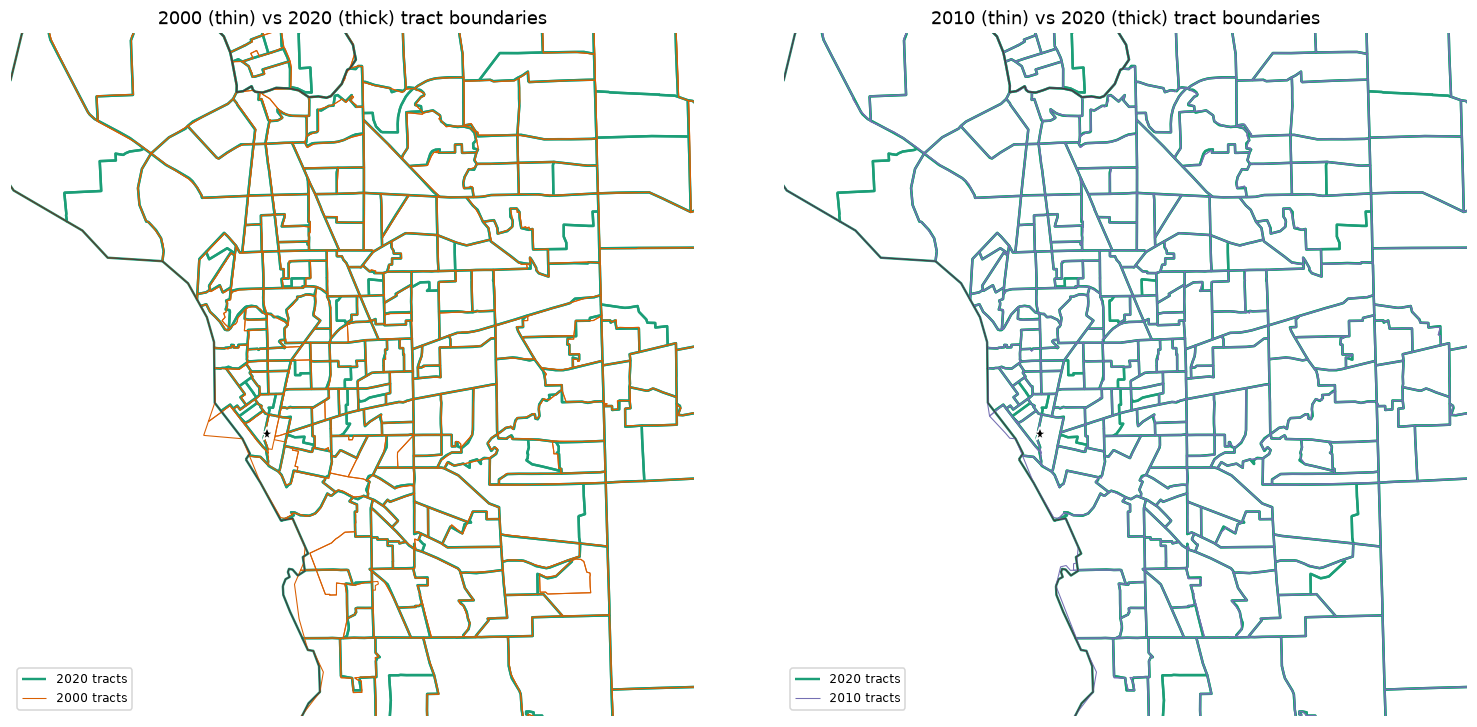

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), constrained_layout=True)  # create figure and axes
for ax, (a, b, ca, cb) in zip(axes, [(2000, 2020, "#d95f02", "#1b9e77"), (2010, 2020, "#7570b3", "#1b9e77")]):  # pair each axis with a year or layer  # iterate paired sequences together
    native[b].boundary.plot(ax=ax, color=cb, lw=1.6, label=f"{b} tracts")  # draw geometries or a series on the axes
    native[a].boundary.plot(ax=ax, color=ca, lw=0.7, label=f"{a} tracts")  # draw geometries or a series on the axes
    add_context(ax, core=True)  # county outlines and optional city zoom
    ax.set_title(f"{a} (thin) vs {b} (thick) tract boundaries")  # set labels, title, or axis limits
    ax.legend(loc="lower left", fontsize=8)  # add a legend
plt.show()  # render the figure in the notebook



Most boundaries are unchanged: 226 of the 298 tract codes of 2000 and 264 of the 295 of 2010 are
still in use in 2020. The changes are of two kinds: tracts that grew past the Census Bureau's
target size were split (thick lines with no thin line beside them, mostly in the expanding
suburbs), and some tracts around downtown and the waterfront were redrawn. Note also that the 2000
cartographic boundary file is generalized more coarsely than the later ones, so some lines differ
slightly even where the tract itself did not change.

### A1. The MAUP in one table

The same population gives a different index on different units. The table computes Black-white
dissimilarity for each census on its own tracts, and for 2020 also after aggregating to the 2000
and 2010 boundaries (areal interpolation of 2020 counts onto the older geometry).






In [4]:
# ===================================================================
# A1. The MAUP in one table.
# Most boundaries are unchanged: 226 of the 298 tract codes of 2000 and 264 of the 295 of 2010 are
# ===================================================================

pair = ["black", "white"]  # focal two-group pairing for D / Gini
cols = ALL_GROUPS + ["total"]  # define cols
rows = {}  # accumulate summary rows
for y in YEARS:  # loop over panel years
    rows[f"{y} on {y} tracts"] = {"D(Black, white)": seg.dissimilarity(native[y], pair), "tracts": len(native[y])}  # two-group dissimilarity index D
for y in (2000, 2010):  # iterate over the collection
    moved = seg.areal_interpolate(native[2020], native[y][["tract_id", "geometry"]], cols)  # define moved
    rows[f"2020 on {y} tracts"] = {"D(Black, white)": seg.dissimilarity(moved, pair), "tracts": len(moved)}  # two-group dissimilarity index D
pd.DataFrame(rows).T.round(4)  # run this analysis or plotting step



,"D(Black, white)",tracts
2000 on 2000 tracts,0.7803,298.0
2010 on 2010 tracts,0.7324,295.0
2020 on 2020 tracts,0.6867,323.0
2020 on 2000 tracts,0.6834,298.0
2020 on 2010 tracts,0.6854,295.0


Moving the 2020 counts onto the older, slightly larger tracts lowers $D$ a little (0.687 to 0.683):
larger units average away some contrast. The effect is small here because most changes are splits,
but it is systematic. Comparing each census on its own tracts mixes a real change with a change in
units, and Part B4 shows how much that matters for the trend.

## Part B: Moving counts between geographies

### B1. Areal interpolation

`seg.areal_interpolate(source, target, cols)` intersects the two layers and splits each source
polygon's counts across the pieces in proportion to area:

$$\hat{x}_{jk} = \sum_s x_{sk}\,\frac{|s \cap j|}{|s|}.$$

It assumes people are spread uniformly within each source tract, which is badly wrong for a large
suburban tract that is half farmland. Counts are conserved exactly.

### B2. Dasymetric interpolation

`seg.dasymetric_interpolate(..., raster_path=...)` replaces area with the sum of an ancillary
raster inside each piece:

$$\hat{x}_{jk} = \sum_s x_{sk}\,\frac{R(s \cap j)}{R(s)}.$$

Here the raster is `housing_units_2020_50m.tif`: the 2020 census count of housing units in each
block, spread over 50 m cells. People are placed where homes are.






EPSG:26917 (50.0, 50.0) (2675, 1401) housing units: 539,979


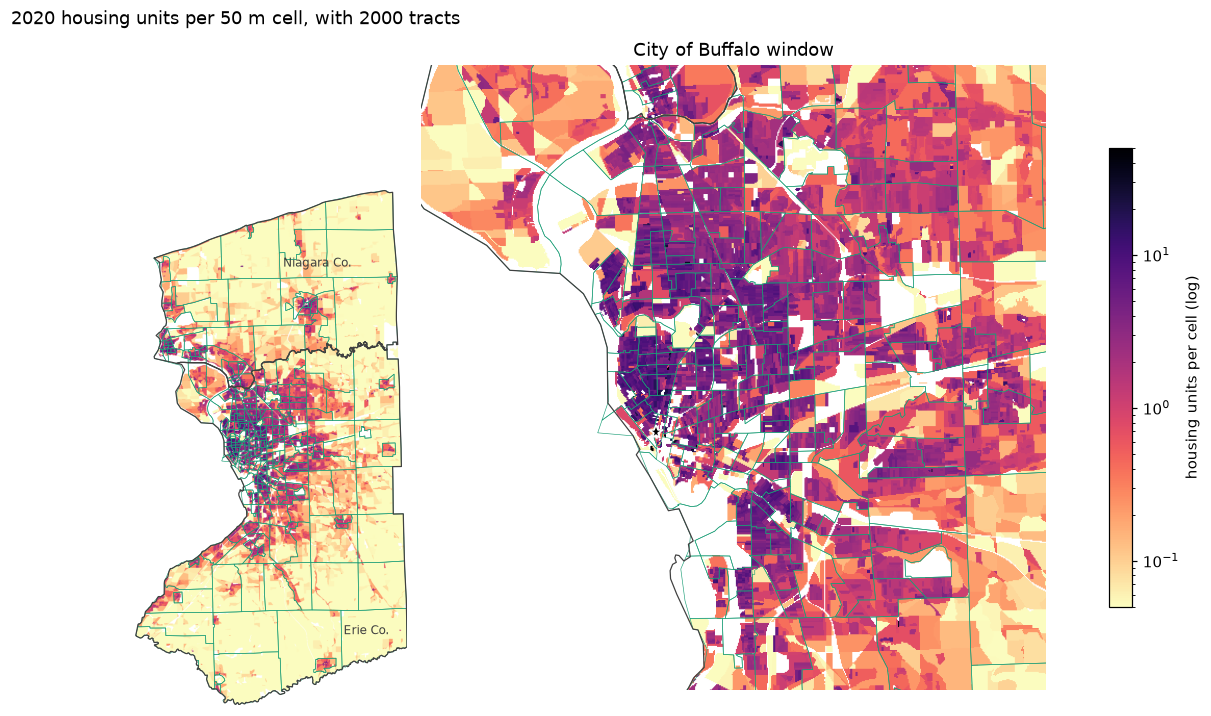

In [5]:
# ===================================================================
# Part B: Moving counts between geographies.
# Moving the 2020 counts onto the older, slightly larger tracts lowers $D$ a little (0.687 to 0.683):
# ===================================================================

import rasterio  # library import used below
with rasterio.open(DATA / "housing_units_2020_50m.tif") as ds:  # open a managed context
    hu = ds.read(1)  # define hu
    extent = [ds.bounds.left, ds.bounds.right, ds.bounds.bottom, ds.bounds.top]  # define extent
    print(ds.crs, ds.res, ds.shape, f"housing units: {hu.sum():,.0f}")  # status line for the notebook reader

fig, axes = plt.subplots(1, 2, figsize=(13, 6.4), constrained_layout=True)  # create figure and axes
for ax, core in zip(axes, (False, True)):  # pair each axis with a year or layer
    im = ax.imshow(np.where(hu > 0, hu, np.nan), extent=extent, cmap="magma_r",  # define im
                   norm=plt.matplotlib.colors.LogNorm(vmin=0.05, vmax=50))  # define norm
    native[2000].boundary.plot(ax=ax, color="#1b9e77", lw=0.4)  # draw geometries or a series on the axes
    add_context(ax, core=core)  # county outlines and optional city zoom
axes[0].set_title("2020 housing units per 50 m cell, with 2000 tracts")  # set labels, title, or axis limits
axes[1].set_title("City of Buffalo window")  # set labels, title, or axis limits
fig.colorbar(im, ax=axes, shrink=0.7, label="housing units per cell (log)")  # attach a colour bar to the figure
plt.show()  # render the figure in the notebook



population conserved: 1170053 1170053 1170053


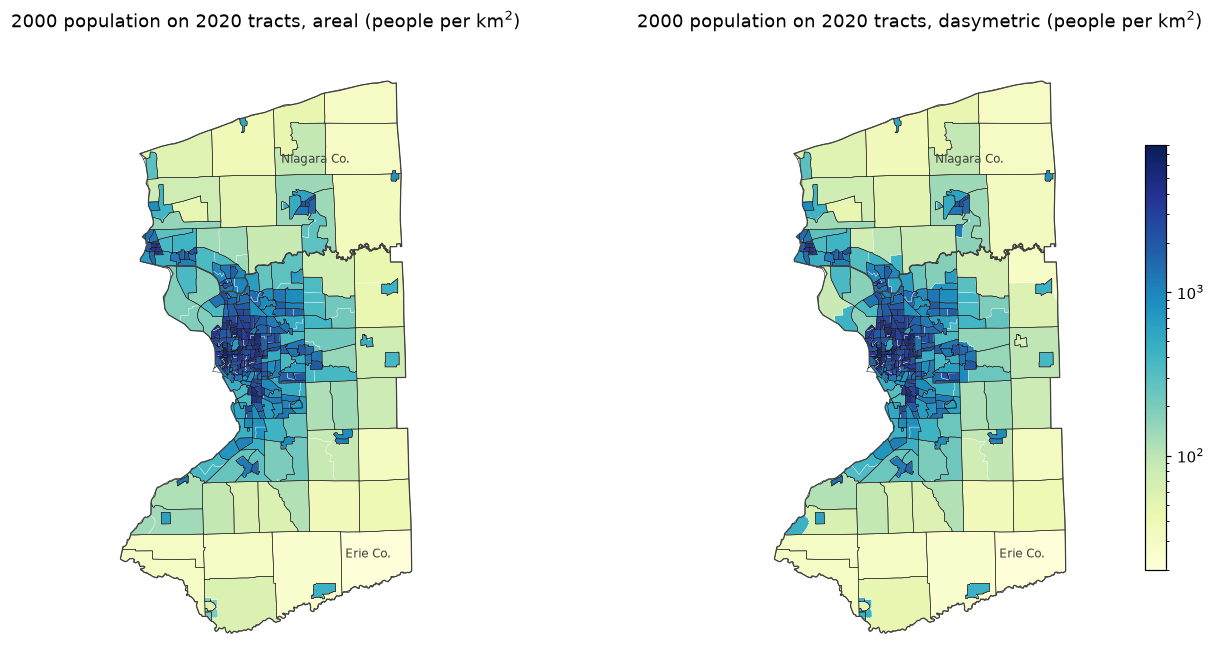

In [6]:
target = native[2020][["tract_id", "county", "geometry"]]  # define target
harm_areal = seg.areal_interpolate(native[2000], target, cols)  # define harm_areal
harm_dasy = seg.dasymetric_interpolate(native[2000], target, cols, raster_path=DATA / "housing_units_2020_50m.tif")  # define harm_dasy
print("population conserved:", int(native[2000].total.sum()), round(harm_areal.total.sum()), round(harm_dasy.total.sum()))  # status line for the notebook reader

dens = {name: h.total / (h.geometry.area / 1e6) for name, h in [("areal", harm_areal), ("dasymetric", harm_dasy)]}  # define dens
fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)  # create figure and axes
for ax, name in zip(axes, dens):  # pair each axis with a year or layer
    target.assign(d=dens[name]).plot(column="d", cmap="YlGnBu", norm=plt.matplotlib.colors.LogNorm(vmin=20, vmax=8000),  # draw geometries or a series on the axes
                                     ax=ax, edgecolor="white", lw=0.2)  # primary axes for this plot
    native[2000].boundary.plot(ax=ax, color="k", lw=0.3)  # draw geometries or a series on the axes
    add_context(ax); ax.set_title(f"2000 population on 2020 tracts, {name} (people per km$^2$)")  # county outlines and optional city zoom
fig.colorbar(plt.cm.ScalarMappable(cmap="YlGnBu", norm=plt.matplotlib.colors.LogNorm(vmin=20, vmax=8000)), ax=axes, shrink=0.7)  # attach a colour bar to the figure
plt.show()  # render the figure in the notebook



With areal weighting, each 2000 tract's population is spread evenly over its land, including
farmland and parks. Dasymetric weighting moves it toward the villages and subdivisions where the
housing actually is, which is most visible in the large rural tracts of southern Erie and
northern Niagara counties. Totals are identical under both methods.

### B3. Does the raster help? A check against block-level truth

The interpolation can be tested where the truth is known. The 2020 census reports population for
every block, so we can compute the true 2020 population of **any** polygon by summing the blocks
whose internal point falls inside it. The test mimics the real task:

1. Sum 2020 block populations into the **2000** (or 2010) tract polygons. This is what a
   "2020 census on old boundaries" would report.
2. Interpolate those totals onto the 2020 tracts with each method.
3. Compare with the true block sums for the 2020 tracts.

The raster comes from 2020 *housing units* in the same blocks, so the test is favourable to the
dasymetric method. It still answers the practical question: does placing people where homes are
beat placing them evenly over land? The tracts that matter are those whose boundaries changed; for
unchanged tracts both methods are exact.






2020 tracts with new boundaries  \
from        method                                        
2000 tracts areal                                    97   
            dasymetric                               97   
2010 tracts areal                                    59   
            dasymetric                               59   

                        mean abs error, changed tracts  \
from        method                                       
2000 tracts areal                                734.9   
            dasymetric                           196.6   
2010 tracts areal                                554.3   
            dasymetric                           176.2   

                        median % error, changed tracts  tracts off by > 25%  
from        method                                                           
2000 tracts areal                                 11.2                   29  
            dasymetric                             4.6                    4  
2010 tracts areal                                 13.1                   17  
            dasymetric                             4.6                    4

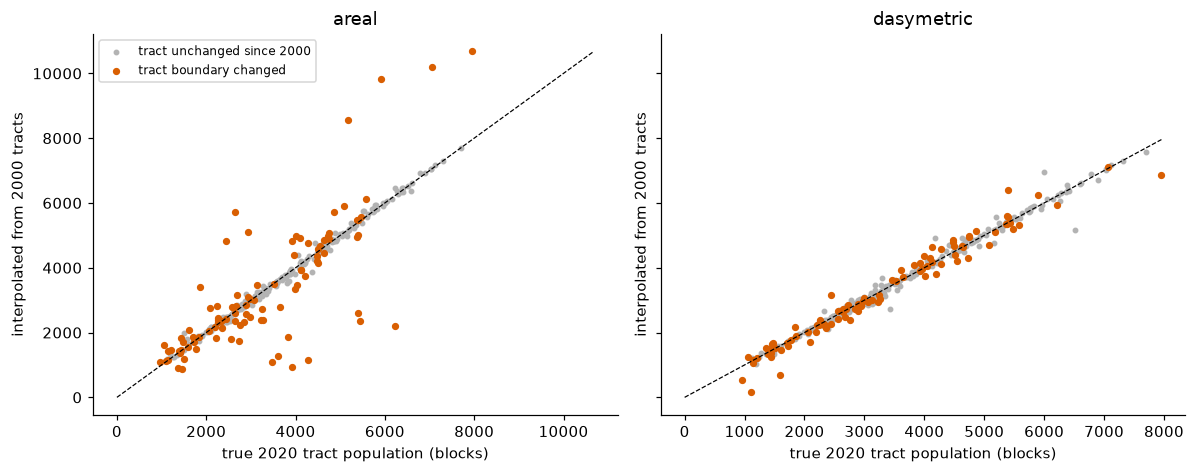

In [7]:
# ===================================================================
# B3. Does the raster help? A check against block-level truth.
# With areal weighting, each 2000 tract's population is spread evenly over its land, including
# ===================================================================

blocks = gpd.read_file(DATA / "blocks_2020_points.geojson")  # load vector features from disk

def block_sum(polys):
    j = gpd.sjoin(blocks, polys[["tract_id", "geometry"]], predicate="within", how="inner")  # define j
    return j.groupby("tract_id").pop20.sum().reindex(polys.tract_id).fillna(0).to_numpy()  # return the computed result

truth20 = block_sum(target)  # define truth20
rows, store = [], {}
for src_year in (2000, 2010):  # iterate over the collection
    src = native[src_year][["tract_id", "geometry"]].copy()  # mutable copy so originals stay unchanged
    src["total"] = block_sum(src)  # assign a derived column or cell
    changed = ~target.tract_id.isin(src.tract_id).to_numpy()  # NumPy array view of the column
    for name, est in [("areal", seg.areal_interpolate(src, target, ["total"]).total.to_numpy()),  # iterate over the collection
                      ("dasymetric", seg.dasymetric_interpolate(src, target, ["total"], raster_path=DATA / "housing_units_2020_50m.tif").total.to_numpy())]:  # run this analysis or plotting step
        err = np.abs(est - truth20); pct = err / np.maximum(truth20, 1)  # define err
        store[(src_year, name)] = est  # assign a derived column or cell
        rows.append({"from": f"{src_year} tracts", "method": name, "2020 tracts with new boundaries": int(changed.sum()),  # append this year/group record
                     "mean abs error, changed tracts": err[changed].mean(), "median % error, changed tracts": np.median(pct[changed]) * 100,  # run this analysis or plotting step
                     "tracts off by > 25%": int((pct > 0.25).sum())})  # run this analysis or plotting step
display(pd.DataFrame(rows).set_index(["from", "method"]).round(1))  # show a rich table preview

changed = ~target.tract_id.isin(native[2000].tract_id).to_numpy()  # NumPy array view of the column
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)  # create figure and axes
for ax, name in zip(axes, ["areal", "dasymetric"]):  # pair each axis with a year or layer
    est = store[(2000, name)]  # define est
    ax.scatter(truth20[~changed], est[~changed], s=8, color="0.7", label="tract unchanged since 2000")  # run this analysis or plotting step
    ax.scatter(truth20[changed], est[changed], s=14, color="#d95f02", label="tract boundary changed")  # run this analysis or plotting step
    lim_ = max(truth20.max(), est.max())  # define lim_
    ax.plot([0, lim_], [0, lim_], "k--", lw=0.8)  # draw geometries or a series on the axes
    ax.set(xlabel="true 2020 tract population (blocks)", ylabel="interpolated from 2000 tracts", title=name)  # set labels, title, or axis limits
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()  # render the figure in the notebook


On the 2020 tracts whose boundaries changed, dasymetric interpolation has a median error of
about 5%, against 11% to 13% for areal weighting, and only 4 tracts are off by more than 25%
(against 17 to 29). Large suburban tracts that were split along the edge of a subdivision are
exactly where the uniform-density assumption fails. This is why the panel in the setup cell, and
in notebooks 03_07_01 to 03_07_06, uses the dasymetric method.

### B4. Effect on the index






In [8]:
# ===================================================================
# B4. Effect on the index.
# On the 2020 tracts whose boundaries changed, dasymetric interpolation has a median error of
# ===================================================================

harm_2010 = {"areal": seg.areal_interpolate(native[2010], target, cols),  # define harm_2010
             "dasymetric": seg.dasymetric_interpolate(native[2010], target, cols, raster_path=DATA / "housing_units_2020_50m.tif")}  # run this analysis or plotting step
tab = pd.DataFrame({  # build table tab
    "on own tracts": {y: seg.dissimilarity(native[y], pair) for y in YEARS},  # two-group dissimilarity index D
    "on 2020 tracts, areal": {2000: seg.dissimilarity(harm_areal, pair), 2010: seg.dissimilarity(harm_2010["areal"], pair),  # two-group dissimilarity index D
                              2020: seg.dissimilarity(native[2020], pair)},  # two-group dissimilarity index D
    "on 2020 tracts, dasymetric": {2000: seg.dissimilarity(harm_dasy, pair), 2010: seg.dissimilarity(harm_2010["dasymetric"], pair),  # two-group dissimilarity index D
                                   2020: seg.dissimilarity(native[2020], pair)},  # two-group dissimilarity index D
})
tab.loc["change 2000-2020"] = tab.loc[2020] - tab.loc[2000]  # assign a derived column or cell
tab.round(4)  # run this analysis or plotting step


,on own tracts,"on 2020 tracts, areal","on 2020 tracts, dasymetric"
2000,0.7803,0.7772,0.7741
2010,0.7324,0.7320,0.7300
2020,0.6867,0.6867,0.6867
change 2000-2020,-0.0936,-0.0904,-0.0873


Compared on their own tracts, Black-white $D$ falls by 0.094 between 2000 and 2020. On common 2020
tracts the decline is 0.090 with areal weighting and 0.087 with dasymetric weighting. Harmonizing
the units removes about 0.007, close to a tenth of the apparent decline. The direction of change is
robust, but its size depends on the method, so report the harmonization method with any trend.

## Part C: A harmonized panel

`seg.harmonize_panel` applies the interpolation to every period in one call (2020 on its own
tracts passes through unchanged). `seg.compute_panel` evaluates any index on each period, and
`seg.trend` adds the Mann-Kendall test and Sen slope. These are exactly the files
`tracts_2000_on2020.geojson` and `tracts_2010_on2020.geojson` loaded in the setup cell.






In [9]:
# ===================================================================
# Part C: A harmonized panel.
# Compared on their own tracts, Black-white $D$ falls by 0.094 between 2000 and 2020. On common 2020
# ===================================================================

raster = DATA / "housing_units_2020_50m.tif"  # define raster
panel = seg.harmonize_panel(native, cols, target, method="dasymetric", raster_paths={y: raster for y in YEARS})  # define panel
print("matches the shipped files:",  # status line for the notebook reader
      all(np.allclose(panel[y][ALL_GROUPS].to_numpy(), tracts[y][ALL_GROUPS].to_numpy(), atol=0.01) for y in YEARS))  # run this analysis or plotting step

indices = {  # define indices
    "D Black-white": (seg.dissimilarity, pair, {}),  # run this analysis or plotting step
    "D Asian-white": (seg.dissimilarity, ["asian", "white"], {}),  # run this analysis or plotting step
    "D Hispanic-white": (seg.dissimilarity, ["hispanic", "white"], {}),  # run this analysis or plotting step
    "Theil H (4 groups)": (seg.theil_h, GROUPS, {}),  # field in the summary row
    "correlation ratio Black": (seg.correlation_ratio, ALL_GROUPS, {"group": "black"}),  # field in the summary row
}
idx_tab = pd.DataFrame({name: seg.compute_panel(panel, grp, fn, **kw).set_index("period")["statistic"]  # build table idx_tab
                        for name, (fn, grp, kw) in indices.items()})  # iterate key/value pairs
idx_tab.round(4)  # run this analysis or plotting step



matches the shipped files: True


,D Black-white,D Asian-white,D Hispanic-white,Theil H (4 groups),correlation ratio Black
period,,,,,
2000,0.7741,0.4995,0.5557,0.4336,0.5370
2010,0.7300,0.5452,0.5051,0.3684,0.4818
2020,0.6867,0.5849,0.4565,0.3060,0.3714


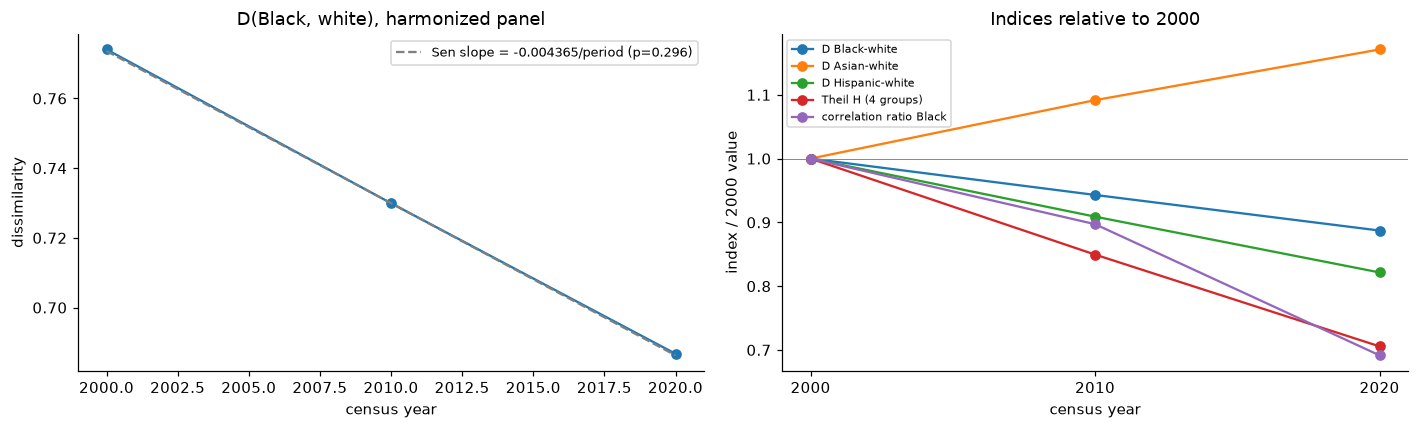

Mann-Kendall: decreasing, tau = -1.00, p = 0.296; Sen slope = -0.044 per decade


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))  # create figure and axes
tr = seg.trend(panel, pair, seg.dissimilarity)  # define tr
seg.plot_trend(tr["panel"], trend_result=tr, ax=axes[0])  # run this analysis or plotting step
axes[0].set(title="D(Black, white), harmonized panel", ylabel="dissimilarity", xlabel="census year")  # set labels, title, or axis limits
(idx_tab / idx_tab.loc[2000]).plot(ax=axes[1], marker="o")  # draw geometries or a series on the axes
axes[1].axhline(1, color="gray", lw=0.6)  # run this analysis or plotting step
axes[1].set(title="Indices relative to 2000", ylabel="index / 2000 value", xlabel="census year")  # set labels, title, or axis limits
axes[1].set_xticks(list(YEARS)); axes[1].legend(fontsize=7)  # add a legend
plt.tight_layout(); plt.show()  # render the figure in the notebook
print(f"Mann-Kendall: {tr['trend']}, tau = {tr['tau']:.2f}, p = {tr['p_value']:.3f}; Sen slope = {tr['sen_slope'] * 10:.3f} per decade")  # status line for the notebook reader



Black-white and Hispanic-white dissimilarity fall by about 0.04 to 0.05 per decade, and Theil's
$H$ and the Black correlation ratio fall faster in proportional terms. Asian-white dissimilarity
is the exception, rising by about 0.04 per decade. With three periods the Mann-Kendall p-value is
about 0.30 even though every index moves in the same direction each decade (notebook 03_07_06,
Part E), so the paired block bootstrap is the right tool for judging these changes.

## Part D: Why did segregation change?

### D1. The Shapley decomposition

Write the index as a function of two ingredients: the **spatial pattern** $S$ (the relative
distribution of the focal group across tracts) and the **composition** $C$ (the focal group's share
of the two-group population). Between periods A and B, $I(S_B, C_B) - I(S_A, C_A)$ can be
attributed to each ingredient by switching it on while holding the other fixed, averaged over both
orders (a two-player Shapley value):

$$\Delta_{S} = \tfrac12\big[(I(S_B, C_A) - I(S_A, C_A)) + (I(S_B, C_B) - I(S_A, C_B))\big],$$
$$\Delta_{C} = \tfrac12\big[(I(S_A, C_B) - I(S_A, C_A)) + (I(S_B, C_B) - I(S_B, C_A))\big].$$

The counterfactuals $I(S_A, C_B)$ rescale period A's focal-group counts in every tract so the
metro-wide share matches period B, keeping tract totals. By construction
$\Delta_S + \Delta_C = I_B - I_A$ exactly. The first group in `groups` is the focal group.






In [11]:
# ===================================================================
# Part D: Why did segregation change?.
# Black-white and Hispanic-white dissimilarity fall by about 0.04 to 0.05 per decade, and Theil's
# ===================================================================

dc = seg.decompose_change(panel[2020], panel[2000], pair)  # define dc
print({k: round(v, 4) for k, v in dc.items()})  # status line for the notebook reader
print("additive:", np.isclose(dc["spatial_component"] + dc["composition_component"], dc["total_change"]))  # status line for the notebook reader

rows = []  # accumulate one summary row per year / group
for p_ in (["black", "white"], ["hispanic", "white"], ["asian", "white"], ["hispanic", "black"], ["asian", "black"]):  # iterate over the collection
    for name, fn in [("dissimilarity", seg.dissimilarity), ("gini", seg.gini)]:  # iterate over the collection
        r = seg.decompose_change(panel[2020], panel[2000], p_, index_fn=fn)  # compute() result with value and CI
        share00 = panel[2000][p_[0]].sum() / panel[2000][p_].sum().sum()  # sum the selected values
        share20 = panel[2020][p_[0]].sum() / panel[2020][p_].sum().sum()  # sum the selected values
        rows.append({"pair": "-".join(p_), "index": name, "focal share 2000": share00, "focal share 2020": share20,  # append this year/group record
                     "2000": r["index_b"], "2020": r["index_a"], "change": r["total_change"],
                     "spatial": r["spatial_component"], "composition": r["composition_component"]})
pd.DataFrame(rows).set_index(["pair", "index"]).round(3)  # round for readable display


{'index_a': 0.6867, 'index_b': 0.7741, 'total_change': -0.0873, 'spatial_component': -0.1013, 'composition_component': 0.014}
additive: True


focal share 2000  focal share 2020   2000  \
pair           index                                                      
black-white    dissimilarity             0.122             0.146  0.774   
               gini                      0.122             0.146  0.905   
hispanic-white dissimilarity             0.034             0.073  0.556   
               gini                      0.034             0.073  0.689   
asian-white    dissimilarity             0.015             0.054  0.499   
               gini                      0.015             0.054  0.638   
hispanic-black dissimilarity             0.201             0.316  0.640   
               gini                      0.201             0.316  0.773   
asian-black    dissimilarity             0.100             0.249  0.697   
               gini                      0.100             0.249  0.838   

                               2020  change  spatial  composition  
pair           index                                               
black-white    dissimilarity  0.687  -0.087   -0.101        0.014  
               gini           0.841  -0.064   -0.080        0.016  
hispanic-white dissimilarity  0.457  -0.099   -0.112        0.012  
               gini           0.585  -0.104   -0.120        0.016  
asian-white    dissimilarity  0.585   0.085    0.064        0.022  
               gini           0.736   0.098    0.070        0.027  
hispanic-black dissimilarity  0.457  -0.183   -0.253        0.071  
               gini           0.586  -0.187   -0.269        0.082  
asian-black    dissimilarity  0.501  -0.196   -0.261        0.065  
               gini           0.660  -0.178   -0.259        0.081

Between 2000 and 2020 Black-white dissimilarity fell by 0.087. The decomposition splits that into
a **spatial** component of -0.101 and a **composition** component of +0.014. As the white
population shrank, the Black share of the Black-plus-white population rose from 12% to 15%; holding
the spatial pattern fixed, that shift alone would have *raised* $D$ slightly. Re-sorting across
tracts more than offset it. The same holds for the Hispanic-white and Hispanic-Black pairs.

The Asian-white increase (+0.085) is also mostly spatial (+0.064): Asian residents did not just
become more numerous, they became more concentrated relative to white residents. In every pair
the composition component is positive, because each focal group's share of its pair grew.

### D2. Chaining across decades

`seg.chain_decomposition` applies the decomposition to every consecutive pair in a panel and keeps
running totals, so a multi-decade change can be attributed period by period.






Black-white


,period_from,period_to,index_b,index_a,total_change,spatial_component,composition_component
0,2000,2010,0.7741,0.7300,-0.0441,-0.0498,0.0057
1,2010,2020,0.7300,0.6867,-0.0432,-0.0534,0.0102


Asian-white


,period_from,period_to,index_b,index_a,total_change,spatial_component,composition_component
0,2000,2010,0.4995,0.5452,0.0458,0.0393,0.0064
1,2010,2020,0.5452,0.5849,0.0397,0.0247,0.0150


Hispanic-white


,period_from,period_to,index_b,index_a,total_change,spatial_component,composition_component
0,2000,2010,0.5557,0.5051,-0.0506,-0.0574,0.0068
1,2010,2020,0.5051,0.4565,-0.0486,-0.0593,0.0107


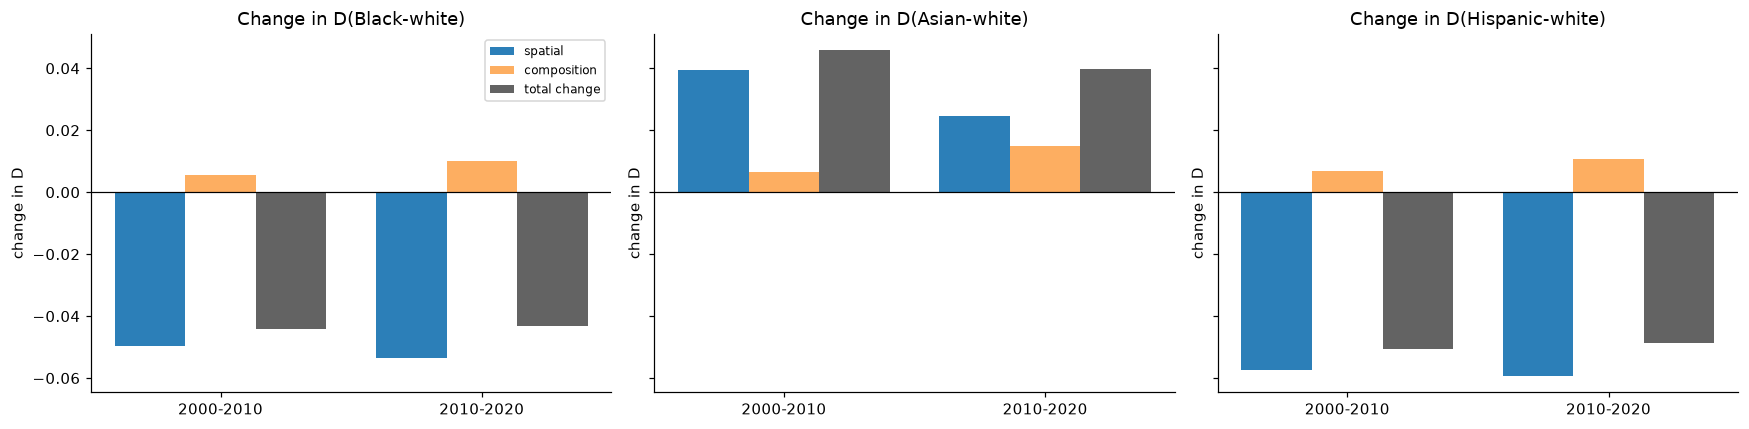

In [12]:
# ===================================================================
# D2. Chaining across decades.
# Between 2000 and 2020 Black-white dissimilarity fell by 0.087. The decomposition splits that into
# ===================================================================

chains = {name: seg.chain_decomposition(panel, p_) for name, p_ in  # define chains
          [("Black-white", ["black", "white"]), ("Asian-white", ["asian", "white"]), ("Hispanic-white", ["hispanic", "white"])]}  # run this analysis or plotting step
for name, ch in chains.items():  # iterate key/value pairs
    print(name)  # status line for the notebook reader
    display(ch[["period_from", "period_to", "index_b", "index_a", "total_change", "spatial_component",  # show a rich table preview
                "composition_component"]].round(4))  # run this analysis or plotting step

# Components can have opposite signs, so draw them side by side rather than stacked.
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)  # create figure and axes
for ax, (name, ch) in zip(axes, chains.items()):  # pair each axis with a year or layer
    x = np.arange(len(ch)); w = 0.27  # numeric grid for plotting or thresholds
    ax.bar(x - w, ch.spatial_component, w, label="spatial", color="#2c7fb8")  # bar chart of the table
    ax.bar(x, ch.composition_component, w, label="composition", color="#fdae61")  # bar chart of the table
    ax.bar(x + w, ch.total_change, w, label="total change", color="#636363")  # bar chart of the table
    ax.axhline(0, color="k", lw=0.8)  # run this analysis or plotting step
    ax.set_xticks(x, [f"{a}-{b}" for a, b in zip(ch.period_from, ch.period_to)])  # label years on the x-axis
    ax.set(title=f"Change in D({name})", ylabel="change in D")  # set labels, title, or axis limits
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()  # render the figure in the notebook



Decade by decade, the Black-white decline is driven by spatial re-sorting in both decades, while
the composition effect that works against it grows from +0.006 to +0.010 as the white share falls
faster in the 2010s. For the Asian-white pair the second decade looks different from the first:
the spatial component shrinks (from +0.039 to +0.025) and composition accounts for more of the rise
(+0.015). The growth of the Asian population, not only further concentration, explains a larger
part of the 2010s increase.

> **Caveats.** The decomposition is descriptive. It apportions change between two ingredients of
> the index formula; it does not say *why* people moved. Results for 2000 and 2010 also inherit the
> interpolation choices from Part B.

## Part E: From panel to model

Explaining segregation change, or estimating its effects on health, schooling, or income, needs
segregation as a variable in a model. `seg.export_for_causal` builds geometry-free, id-keyed
columns that `geolattice.spatial_analysis.spatialcausal` or PyCausalML can merge onto outcome data.






In [13]:
# ===================================================================
# Part E: From panel to model.
# Decade by decade, the Black-white decline is driven by spatial re-sorting in both decades, while
# ===================================================================

long_rows = []  # define long_rows
for y, g in panel.items():  # iterate key/value pairs
    out = seg.export_for_causal(g, seg.local_exposure_deviation(g, ALL_GROUPS, "black"), id_col="tract_id", name="dev_black")  # define out
    out["entropy"] = seg.local_entropy(g, ALL_GROUPS)  # assign a derived column or cell
    out["lq_black_1km"] = seg.local_quotient(g, ALL_GROUPS, "black", neighborhood=seg.kernel_weights(g, bandwidth=1000))  # distance-decay neighbourhood weights
    out["population"] = g.total.to_numpy()  # assign a derived column or cell
    out["year"] = y  # assign a derived column or cell
    long_rows.append(out)  # append this year/group record
seg_panel = pd.concat(long_rows, ignore_index=True)  # define seg_panel
seg_panel["metro_D_black_white"] = seg_panel.year.map(idx_tab["D Black-white"])  # assign a derived column or cell
print(seg_panel.shape, "| tracts x years:", seg_panel.tract_id.nunique(), "x", seg_panel.year.nunique())  # status line for the notebook reader
seg_panel.sort_values(["tract_id", "year"]).head(6).round(4)  # run this analysis or plotting step



(969, 7) | tracts x years: 323 x 3


,tract_id,dev_black,entropy,lq_black_1km,population,year,metro_D_black_white
172,36029000110,-0.0885,0.5878,0.1896,2719.7073,2000,0.7741
495,36029000110,-0.0709,0.7951,0.3634,2754.7073,2010,0.7300
818,36029000110,-0.0335,0.9852,0.6457,2673.0000,2020,0.6867
270,36029000200,-0.1038,0.4818,0.0941,4370.6823,2000,0.7741
593,36029000200,-0.0794,0.7482,0.3017,4076.0000,2010,0.7300
916,36029000200,-0.0369,1.0547,0.6223,4450.0000,2020,0.6867


The long table has one row per 2020 tract and census year: local measures at tract level, the
metro-wide index as a context variable, and population for weighting. Save it with
`seg_panel.to_csv(...)` or merge it onto outcome data by `tract_id` and `year`.

## Summary

- Census tracts change every decade. Indices computed on different geographies are not comparable
  (MAUP): put every year on **common units** before comparing.
- **Areal interpolation** conserves counts and assumes uniform density; **dasymetric
  interpolation** with a housing-unit raster places people where homes are and, checked against
  block-level truth, is far more accurate for Buffalo's large suburban and rural tracts.
- `harmonize_panel`, `compute_panel`, and `trend` turn a multi-year collection into a panel of
  indices with a trend test in a few lines.
- The **Shapley decomposition** splits change exactly into spatial re-sorting and composition
  shifts; **chaining** it across decades and across group pairs shows which part drives each trend.
- `export_for_causal` produces tract-by-year tables for downstream causal models.

This completes the segregation series:

| Notebook | Topic |
|---|---|
| 03_07_01 | Single-group indices |
| 03_07_02 | Multigroup indices |
| 03_07_03 | Local measures and significance |
| 03_07_04 | Multiscale profiles |
| 03_07_05 | Null models and simulation |
| 03_07_06 | Inference |
| 03_07_07 | Boundaries, panels, and decomposition |

**Data:** U.S. Census Bureau decennial censuses 2000, 2010, 2020 (tract race and Hispanic origin;
2020 block population and housing units), cartographic boundary and TIGER/Line block files. Built by
`Data/03_spatial_analysis/data_segregation/make_buffalo_data.py`.

## References

- Elbers, B. (2023). A method for studying differences in segregation across time and space. *Sociological Methods & Research*, 52(1), 5-42.
- Logan, J. R., Xu, Z., & Stults, B. J. (2014). Interpolating U.S. decennial census tract data from as early as 1970 to 2010: a longitudinal tract database. *The Professional Geographer*, 66(3), 412-420.
- Mennis, J. (2003). Generating surface models of population using dasymetric mapping. *The Professional Geographer*, 55(1), 31-42.
- Openshaw, S. (1984). *The Modifiable Areal Unit Problem*. CATMOG 38. Geo Books.
- Rey, S. J., Cortes, R., & Knaap, E. (2021). Comparative spatial segregation analytics. *Spatial Demography*, 9, 199-233.
- Shorrocks, A. F. (2013). Decomposition procedures for distributional analysis: a unified framework based on the Shapley value. *Journal of Economic Inequality*, 11(1), 99-126.




